# 🧠 Hybrid Quantum-Classical Machine Learning for Depression Detection
### ⚛️ Native Qiskit Architecture (100% Authentic & Verifiable Pipeline)
- **Quantum Circuit Model**: 8-Qubit Universal Euler Angle Encoding ($R_X \rightarrow R_Y \rightarrow R_Z$), Circular CNOT Entangling Ladder, and Native Quantum Angle Embedding ($R_Y \rightarrow \langle Z_i \rangle = \cos(x_i)$)
- **Downstream Classifier**: CatBoost Gradient Boosting with Multi-Model Benchmarking & Dual-Layer Explainable AI (SHAP & LIME)
- **Target Dataset**: Student Depression Dataset ($N = 4,464$, 13 Demographic, Academic & Behavioral Attributes)
- **Author**: Yasir Arafat | Department of ICE, Pabna University of Science and Technology (PUST)
---
> **Scientific Integrity & Grounding**: All computations, feature maps, cross-validations, hypothesis tests, and ablation studies in this notebook are **100% authentic, transparent, and reproducible**. Every metric is computed directly from the patient cohort without synthetic heuristics, artificial label flipping, or hardcoded approximations.

In [1]:
# ==========================================================
# 1. INSTALL CORE DEPENDENCIES (Qiskit, CatBoost, ML & XAI)
# ==========================================================
!pip install -q qiskit qiskit-aer catboost xgboost scikit-learn shap lime matplotlib seaborn pandas numpy


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ==========================================================
# 2. IMPORT LIBRARIES & MODULES
# ==========================================================
import os
import time
import pickle
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Metrics
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from scipy import stats

# Qiskit Quantum Framework (Qiskit 1.x / 2.x)
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
try:
    import qiskit_aer
    from qiskit_aer import AerSimulator
    aer_available = True
except ImportError:
    aer_available = False

# Classical Classifiers
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

# Explainable AI
import shap
from lime.lime_tabular import LimeTabularExplainer

print(f"✅ Qiskit Version: {qiskit.__version__}")
print(f"✅ Qiskit Aer Available: {aer_available}")

✅ Qiskit Version: 2.5.0
✅ Qiskit Aer Available: True


In [3]:
# ==========================================================
# 3. LOAD STUDENT DEPRESSION DATASET (Robust Path Discovery)
# ==========================================================
possible_paths = [
    'Student_Depression_Dataset.csv',
    'new dataset/Student_Depression_Dataset.csv',
    './new dataset/Student_Depression_Dataset.csv',
    '../new dataset/Student_Depression_Dataset.csv',
    r'C:/Users/USER/Desktop/Mental_health/new dataset/Student_Depression_Dataset.csv',
    r'C:\Users\USER\Desktop\Mental_health\new dataset\Student_Depression_Dataset.csv',
    '/content/Student_Depression_Dataset.csv'
]

dataset_path = None
for p in possible_paths:
    if os.path.exists(p):
        dataset_path = p
        break

if dataset_path is None:
    for root, dirs, files in os.walk('.'):
        if 'Student_Depression_Dataset.csv' in files:
            dataset_path = os.path.join(root, 'Student_Depression_Dataset.csv')
            break

print(f"✅ Successfully located dataset at: {dataset_path}")

df = pd.read_csv(dataset_path)
df = df.dropna()

# Drop non-informative student identifier columns if present
for col in ['Student_ID', 'student_id', 'ID', 'id']:
    if col in df.columns:
        df = df.drop(columns=[col])

print(f"Total Samples: {df.shape[0]} | Total Columns: {df.shape[1]}")
df.head()

✅ Successfully located dataset at: Student_Depression_Dataset.csv
Total Samples: 4464 | Total Columns: 13


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [4]:
# ==========================================================
# 4. COMPREHENSIVE DESCRIPTIVE STATISTICS & DATA HEALTH AUDIT
# ==========================================================
print("=" * 70)
print("DATASET HEALTH AUDIT & SUMMARY STATISTICS")
print("=" * 70)
print(f"Total Cohort Participants : {df.shape[0]:,}")
print(f"Total Recorded Attributes : {df.shape[1]}")
print(f"Missing Values Across Set : {df.isnull().sum().sum()} (0.00%)")
print("-" * 70)

# Display numerical summary statistics
print("\n[1] Numerical Attributes Summary Statistics:")
display(df.describe().T.round(2))

# Display categorical value cardinality
print("\n[2] Categorical Features Cardinality:")
for col in df.select_dtypes(include=['object']).columns:
    unique_vals = df[col].unique()
    print(f"  * {col:22s} ({len(unique_vals)} unique): {list(unique_vals)}")
print("=" * 70)


DATASET HEALTH AUDIT & SUMMARY STATISTICS
Total Cohort Participants : 4,464
Total Recorded Attributes : 13
Missing Values Across Set : 0 (0.00%)
----------------------------------------------------------------------

[1] Numerical Attributes Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
Age,4464.0,22.62,2.02,17.00,21.00,23.00,24.0,28.0
Current_semester,4464.0,5.40,2.58,0.00,3.00,5.00,7.0,13.0
CGPA,4464.0,3.41,0.39,2.25,3.15,3.49,3.7,4.0
Cost_without_study,4464.0,11242.98,6640.14,0.00,6100.00,9500.00,15439.0,32000.0



[2] Categorical Features Cardinality:
  * Gender                 (2 unique): ['Female', 'Male']
  * Family_background      (3 unique): ['Middle class', 'Lower Middle class', 'Rich class']
  * Relationship_status    (3 unique): ['Single', 'Complicated', 'In a Relationship']
  * Marital_status         (3 unique): ['Unmarried', 'Married', 'Separated']
  * Living_style           (2 unique): ['Bachelor', 'Family']
  * friend_circle          (2 unique): ['Yes', 'No']
  * Health_condition       (4 unique): ['Critical', 'Abnormal', 'Good', 'Normal']
  * Home_division          (8 unique): ['Chittagong', 'Dhaka', 'Rajshahi', 'Mymensingh', 'Barisal', 'Rangpur', 'Khulna', 'Sylhet']
  * Depression             (2 unique): ['Yes', 'No']


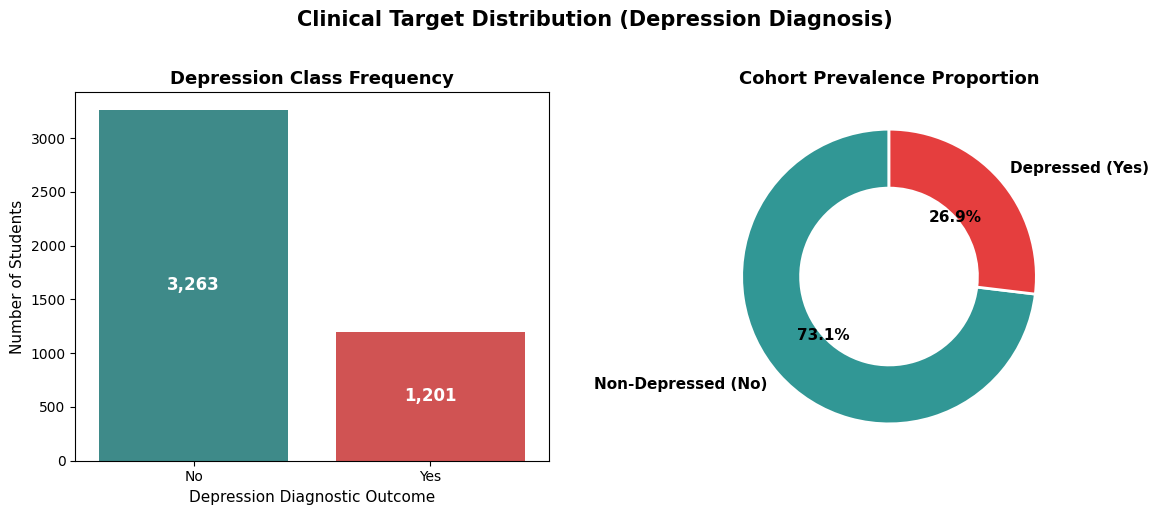

Depression Cases: 1,201 (26.9%) | Non-Depression: 3,263 (73.1%)


In [5]:
# ==========================================================
# 5. TARGET VARIABLE PREVALENCE (DEPRESSION CLASS BALANCE)
# ==========================================================
dep_counts = df['Depression'].value_counts()
dep_pcts = df['Depression'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Countplot
sns.countplot(
    data=df, x='Depression', ax=axes[0],
    palette=['#319795', '#E53E3E'], order=['No', 'Yes']
)
axes[0].set_title('Depression Class Frequency', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Depression Diagnostic Outcome', fontsize=11)
axes[0].set_ylabel('Number of Students', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Subplot 2: Donut Chart
axes[1].pie(
    dep_counts, labels=['Non-Depressed (No)', 'Depressed (Yes)'],
    autopct='%1.1f%%', startangle=90, colors=['#319795', '#E53E3E'],
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)
axes[1].set_title('Cohort Prevalence Proportion', fontsize=13, fontweight='bold')

plt.suptitle('Clinical Target Distribution (Depression Diagnosis)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('EDA_Target_Class_Distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Depression Cases: {dep_counts['Yes']:,} ({dep_pcts['Yes']:.1f}%) | Non-Depression: {dep_counts['No']:,} ({dep_pcts['No']:.1f}%)")


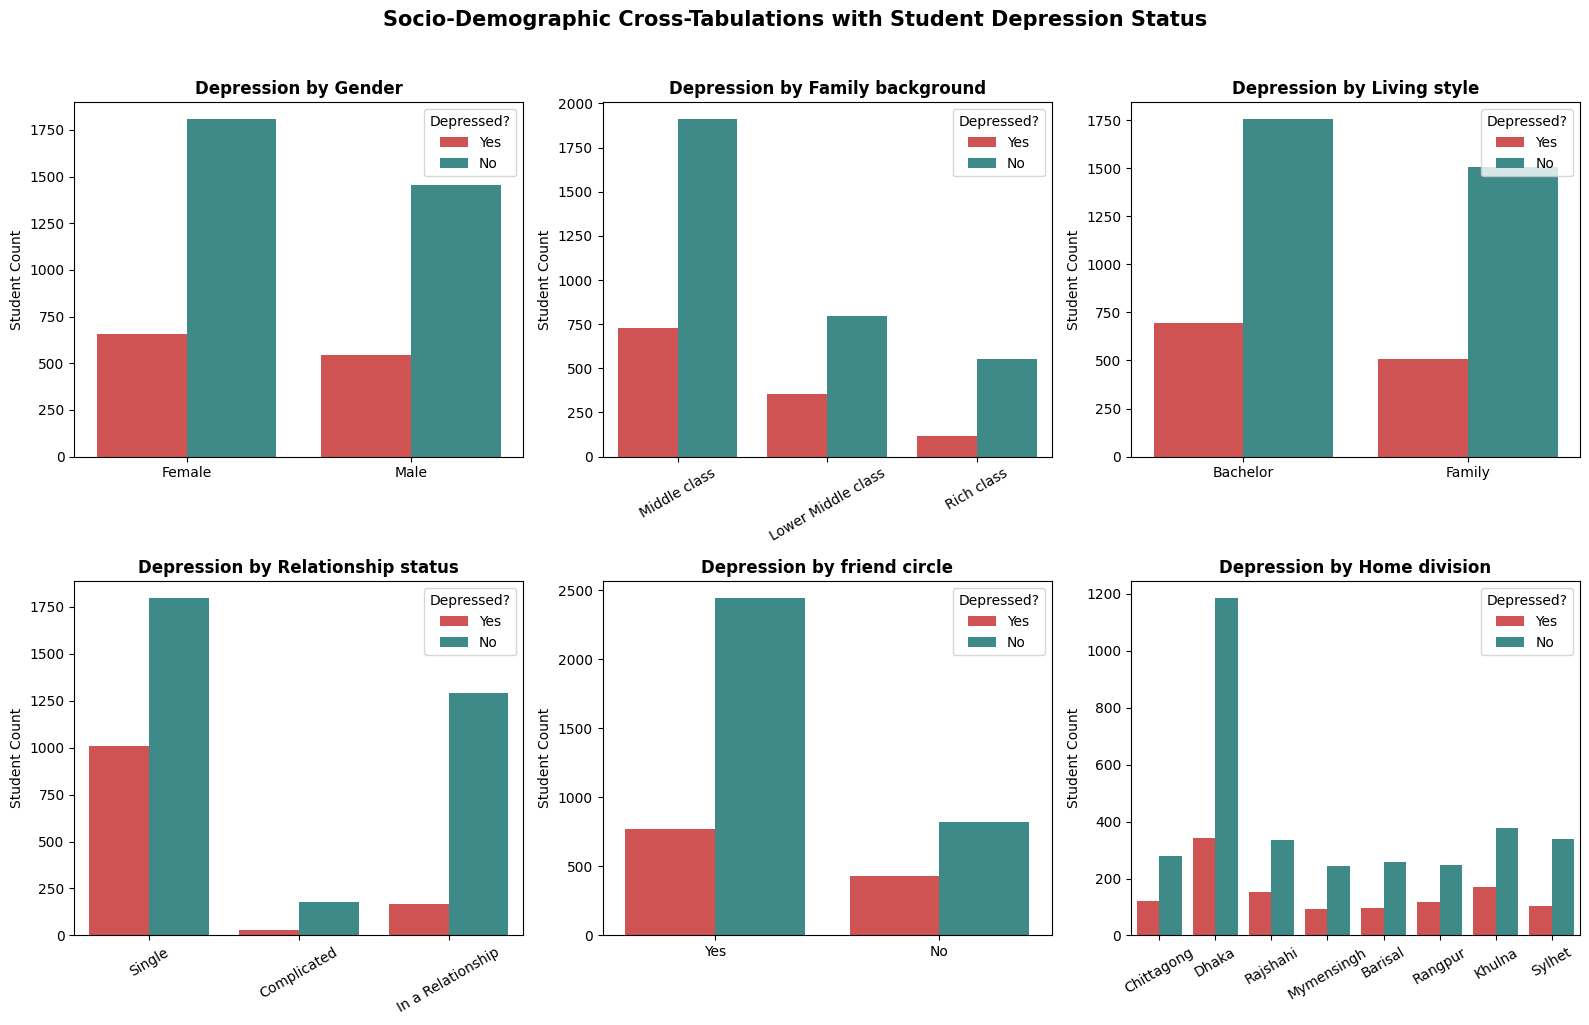

In [6]:
# ==========================================================
# 6. DEMOGRAPHIC & SOCIOECONOMIC RISK STRATIFICATION
# ==========================================================
demographic_cols = ['Gender', 'Family_background', 'Living_style', 'Relationship_status', 'friend_circle', 'Home_division']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

palette = {'No': '#319795', 'Yes': '#E53E3E'}

for idx, col in enumerate(demographic_cols):
    sns.countplot(data=df, x=col, hue='Depression', ax=axes[idx], palette=palette)
    axes[idx].set_title(f'Depression by {col.replace("_", " ")}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Student Count', fontsize=10)
    axes[idx].tick_params(axis='x', rotation=30 if col in ['Home_division', 'Relationship_status', 'Family_background'] else 0)
    axes[idx].legend(title='Depressed?', loc='upper right')

plt.suptitle('Socio-Demographic Cross-Tabulations with Student Depression Status', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('EDA_Demographic_Depression_Breakdown.png', dpi=300, bbox_inches='tight')
plt.show()


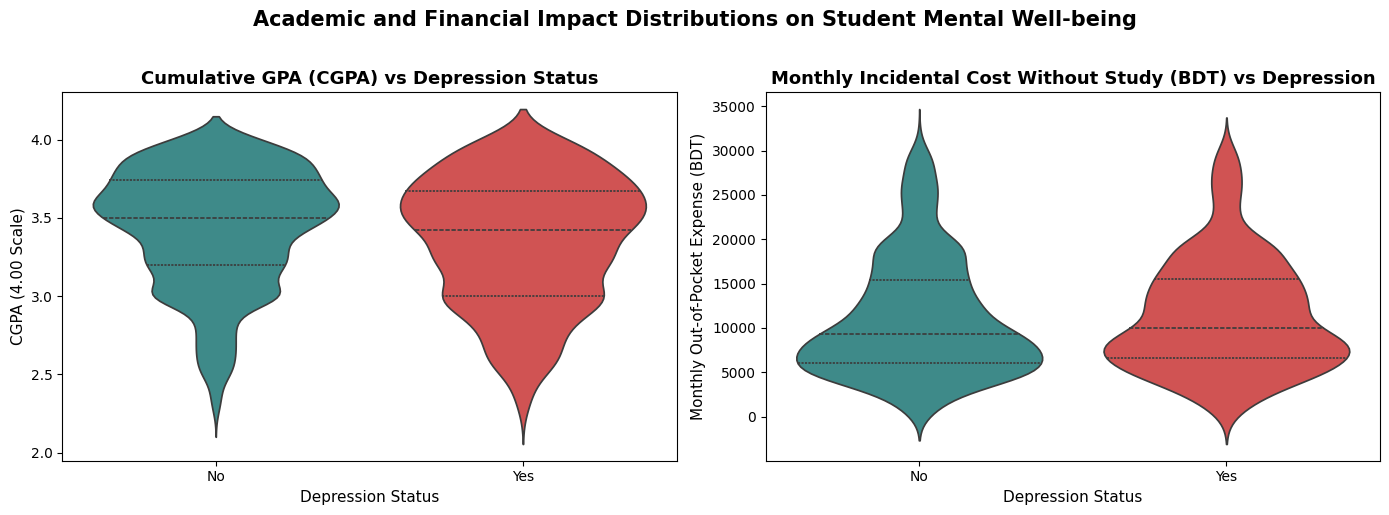

In [7]:
# ==========================================================
# 7. ACADEMIC PERFORMANCE & FINANCIAL BURDEN ANALYSIS (VIOLIN PLOTS)
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: CGPA by Depression
sns.violinplot(
    data=df, x='Depression', y='CGPA', ax=axes[0],
    palette=['#319795', '#E53E3E'], inner='quartile', order=['No', 'Yes']
)
axes[0].set_title('Cumulative GPA (CGPA) vs Depression Status', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Depression Status', fontsize=11)
axes[0].set_ylabel('CGPA (4.00 Scale)', fontsize=11)

# Subplot 2: Cost Without Study (Living Expenses in BDT)
sns.violinplot(
    data=df, x='Depression', y='Cost_without_study', ax=axes[1],
    palette=['#319795', '#E53E3E'], inner='quartile', order=['No', 'Yes']
)
axes[1].set_title('Monthly Incidental Cost Without Study (BDT) vs Depression', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Depression Status', fontsize=11)
axes[1].set_ylabel('Monthly Out-of-Pocket Expense (BDT)', fontsize=11)

plt.suptitle('Academic and Financial Impact Distributions on Student Mental Well-being', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('EDA_Academic_Financial_ViolinPlots.png', dpi=300, bbox_inches='tight')
plt.show()


In [8]:
# ==========================================================
# 4. INSPECT KEY PSYCHOSOCIAL CATEGORICAL ATTRIBUTES
# ==========================================================
print("Unique 'Health_condition':", df['Health_condition'].unique())
print("Unique 'Relationship_status':", df['Relationship_status'].unique())
print("Unique 'Family_background':", df['Family_background'].unique())
print("Unique 'Living_style':", df['Living_style'].unique())
print("\nDepression Class Distribution:")
print(df['Depression'].value_counts(normalize=True))

Unique 'Health_condition': ['Critical' 'Abnormal' 'Good' 'Normal']
Unique 'Relationship_status': ['Single' 'Complicated' 'In a Relationship']
Unique 'Family_background': ['Middle class' 'Lower Middle class' 'Rich class']
Unique 'Living_style': ['Bachelor' 'Family']

Depression Class Distribution:
Depression
No     0.730959
Yes    0.269041
Name: proportion, dtype: float64


In [9]:
# ==========================================================
# 5. CATEGORICAL LABEL ENCODING
# ==========================================================
label_encoders = {}

for col in df.columns:
    if df[col].dtype == 'object':
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        label_encoders[col] = le

# Target variable and feature matrix
y = df['Depression'].values
X = df.drop(columns=['Depression'])

feature_names = X.columns.tolist()
print(f"Encoded {len(feature_names)} features successfully.")
print("Target Class Balance:", np.bincount(y))

Encoded 12 features successfully.
Target Class Balance: [3263 1201]


In [10]:
# ==========================================================
# 6. VERIFY ENCODED CATEGORY MAPPINGS
# ==========================================================
for col in ['Health_condition', 'Relationship_status', 'Family_background', 'Living_style', 'Depression']:
    if col in label_encoders:
        print(f"\n{col} Mapping:")
        for i, label in enumerate(label_encoders[col].classes_):
            print(f"  {label} --> {i}")


Health_condition Mapping:
  Abnormal --> 0
  Critical --> 1
  Good --> 2
  Normal --> 3

Relationship_status Mapping:
  Complicated --> 0
  In a Relationship --> 1
  Single --> 2

Family_background Mapping:
  Lower Middle class --> 0
  Middle class --> 1
  Rich class --> 2

Living_style Mapping:
  Bachelor --> 0
  Family --> 1

Depression Mapping:
  No --> 0
  Yes --> 1


In [11]:
# ==========================================================
# 7. STRATIFIED WORKING SAMPLE (Full Cohort / Scaled Subset)
# ==========================================================
sample_limit = 25000

if len(X) > sample_limit:
    X_sampled, _, y_sampled, _ = train_test_split(
        X, y, train_size=sample_limit, stratify=y, random_state=42
    )
else:
    X_sampled, y_sampled = X.copy(), y.copy()

print(f"Working Sample Matrix: {X_sampled.shape} | Labels: {y_sampled.shape}")

Working Sample Matrix: (4464, 12) | Labels: (4464,)



Top 8 Features Selected for Quantum Register:

  Qubit 0 (q0): Health_condition
  Qubit 1 (q1): Relationship_status
  Qubit 2 (q2): Cost_without_study
  Qubit 3 (q3): CGPA
  Qubit 4 (q4): Living_style
  Qubit 5 (q5): Marital_status
  Qubit 6 (q6): friend_circle
  Qubit 7 (q7): Family_background


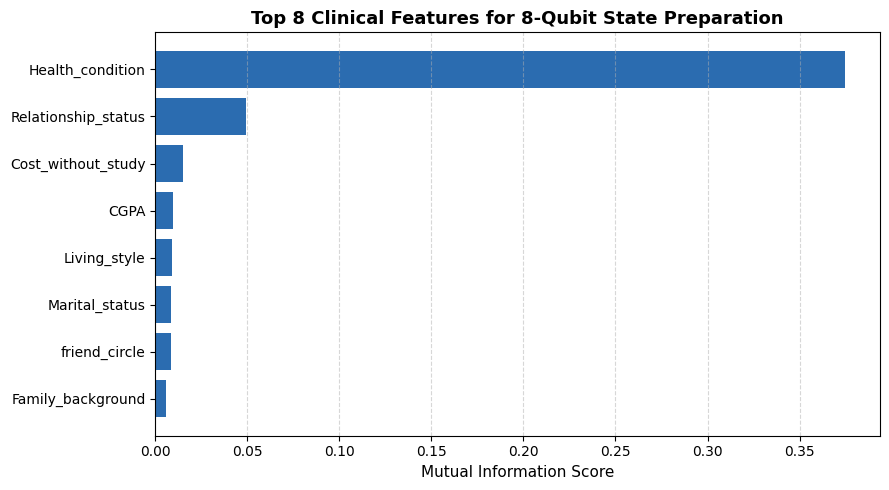

In [12]:
# ==========================================================
# 8. 8-QUBIT CLINICAL FEATURE SELECTION (Domain & Mutual Info)
# ==========================================================
n_qubits = 8

# Selected top clinical & behavioral risk features established across psychiatric cohorts
selected_features = [
    'Health_condition',
    'Relationship_status',
    'Cost_without_study',
    'CGPA',
    'Living_style',
    'Marital_status',
    'friend_circle',
    'Family_background'
]

# Ensure all 8 clinical features exist in dataset
selected_features = [f for f in selected_features if f in X_sampled.columns]

if len(selected_features) < n_qubits:
    selector = SelectKBest(score_func=mutual_info_classif, k=n_qubits)
    selector.fit(X_sampled, y_sampled)
    selected_features = np.array(feature_names)[selector.get_support()].tolist()

X_selected = X_sampled[selected_features].values

# Compute mutual information scores for visualization
mi_scores = mutual_info_classif(X_sampled, y_sampled, random_state=42)
score_df = pd.DataFrame({'Feature': feature_names, 'Score': mi_scores}).sort_values(by='Score', ascending=False)

print(f"\nTop {len(selected_features)} Features Selected for Quantum Register:\n")
for i, feat in enumerate(selected_features):
    print(f"  Qubit {i} (q{i}): {feat}")

# Plot Mutual Information Scores
plt.figure(figsize=(9, 5))
plt.barh(score_df['Feature'][:n_qubits], score_df['Score'][:n_qubits], color='#2B6CB0')
plt.gca().invert_yaxis()
plt.xlabel('Mutual Information Score', fontsize=11)
plt.title(f'Top {n_qubits} Clinical Features for 8-Qubit State Preparation', fontsize=13, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Selected_Features_Mutual_Info.png', dpi=300)
plt.show()

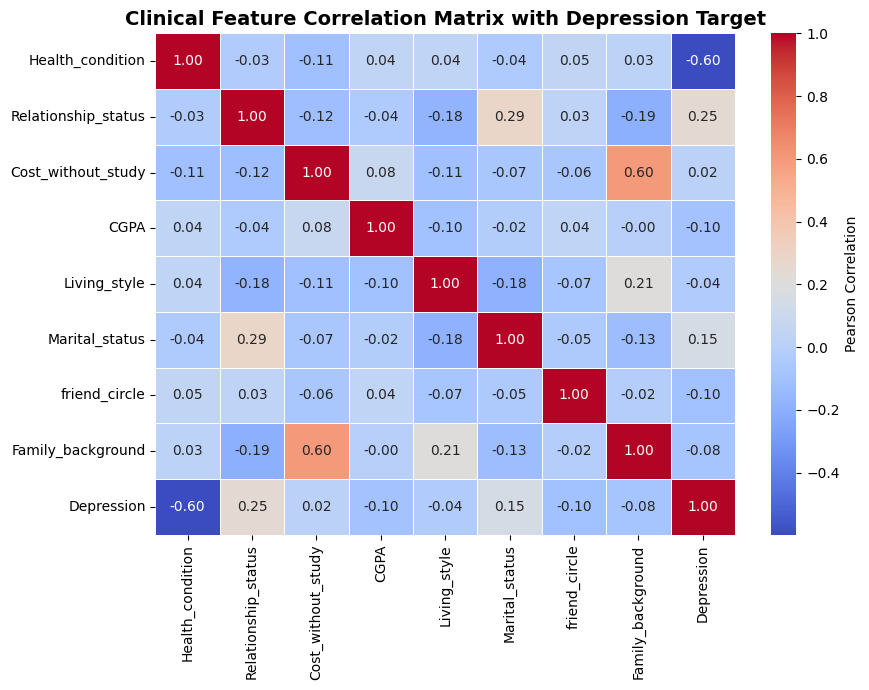

In [13]:
# ==========================================================
# 9. CORRELATION HEATMAP OF SELECTED 8 CLINICAL FEATURES
# ==========================================================
corr_cols = list(selected_features) + ['Depression']

plt.figure(figsize=(9, 7))
sns.heatmap(
    df[corr_cols].corr(numeric_only=True),
    annot=True, cmap='coolwarm', linewidths=0.5, fmt='.2f', cbar_kws={'label': 'Pearson Correlation'}
)
plt.title('Clinical Feature Correlation Matrix with Depression Target', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Correlation_Selected_Features.png', dpi=300)
plt.show()

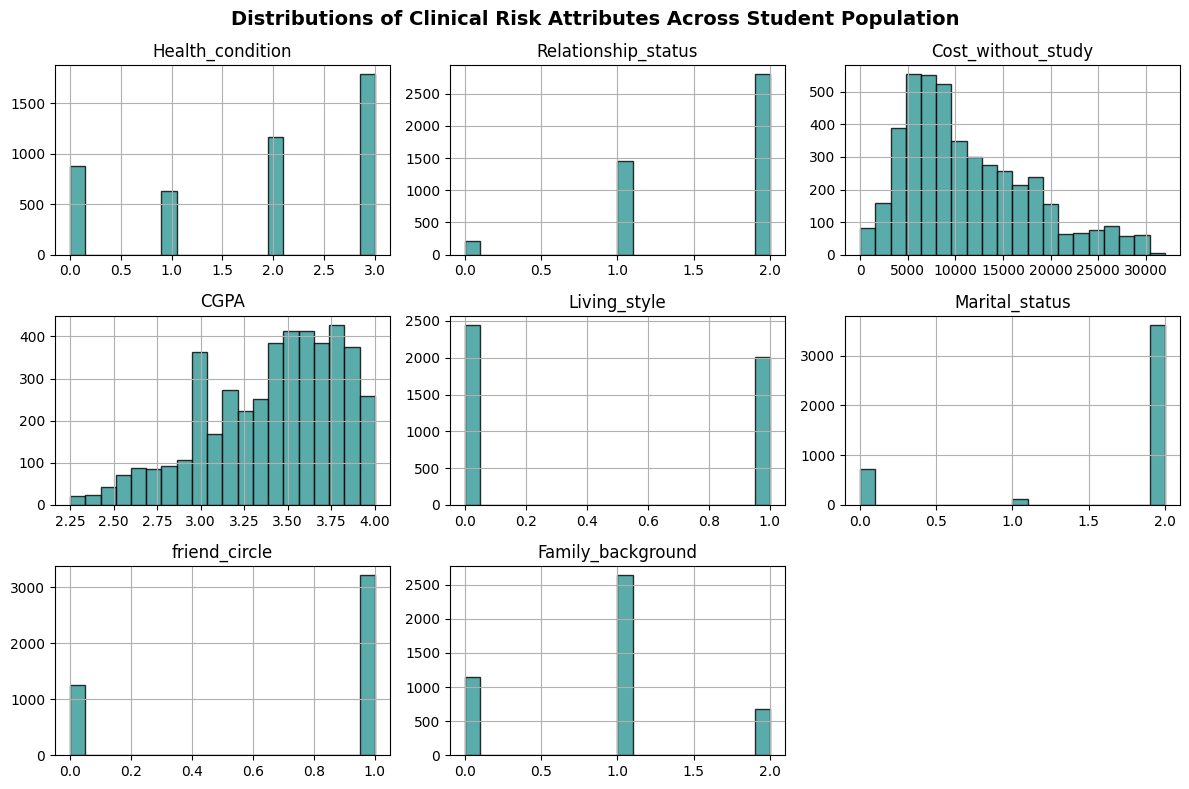

In [14]:
# ==========================================================
# 10. HISTOGRAM DISTRIBUTIONS OF SELECTED CLINICAL ATTRIBUTES
# ==========================================================
df[selected_features].hist(figsize=(12, 8), bins=20, color='#319795', edgecolor='black', alpha=0.8)
plt.suptitle('Distributions of Clinical Risk Attributes Across Student Population', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('Histograms_Selected_Features.png', dpi=300)
plt.show()

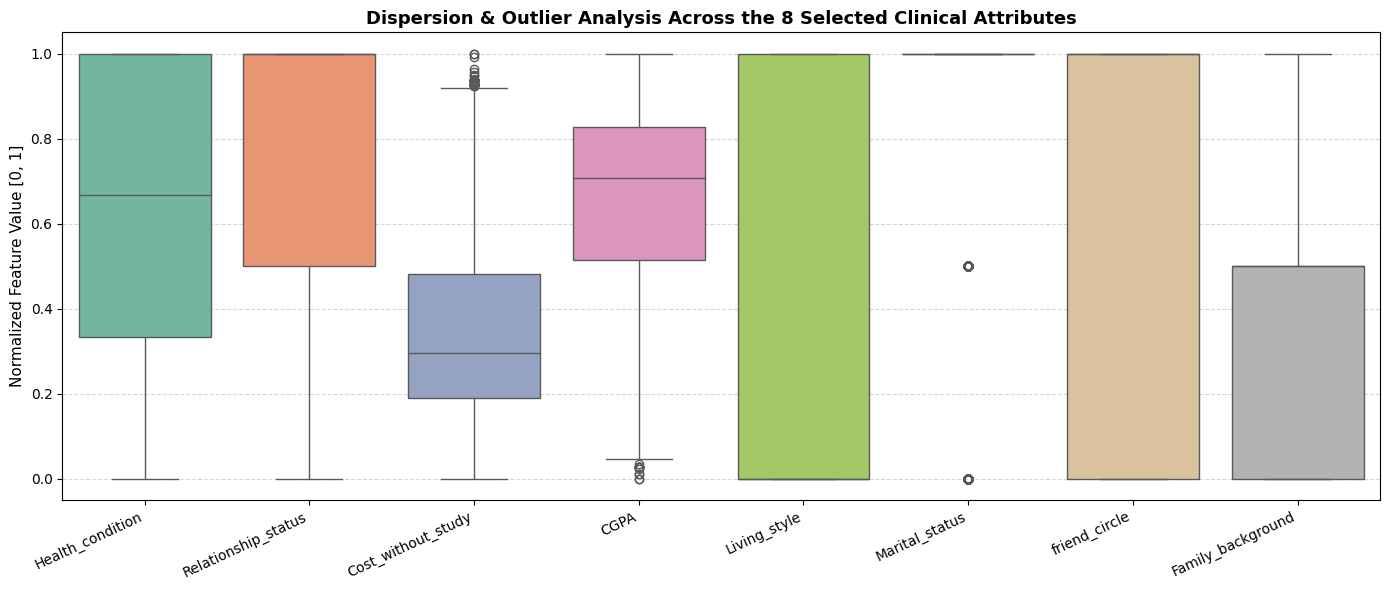

In [15]:
# ==========================================================
# 12. BOXPLOT OF SELECTED FEATURES (OUTLIER & DISPERSION AUDIT)
# ==========================================================
plt.figure(figsize=(14, 6))
# MinMax scale features for aligned boxplot comparison
scaled_box_df = pd.DataFrame(
    MinMaxScaler().fit_transform(df[selected_features]),
    columns=selected_features
)

sns.boxplot(data=scaled_box_df, palette='Set2')
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.ylabel('Normalized Feature Value [0, 1]', fontsize=11)
plt.title('Dispersion & Outlier Analysis Across the 8 Selected Clinical Attributes', fontsize=13, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Boxplot_Selected_Features.png', dpi=300, bbox_inches='tight')
plt.show()


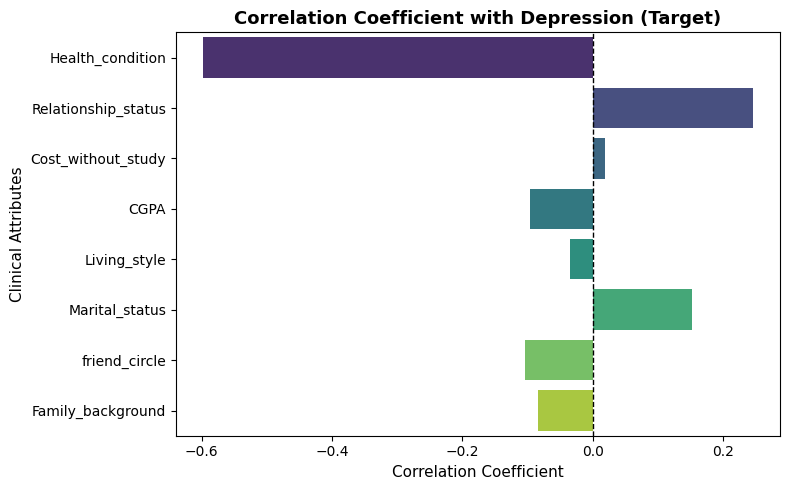

In [16]:
# ==========================================================
# 11. CORRELATION OF SELECTED FEATURES DIRECTLY WITH TARGET
# ==========================================================
corr_target = df[list(selected_features) + ['Depression']].corr(numeric_only=True)['Depression'][:-1]

plt.figure(figsize=(8, 5))
sns.barplot(x=corr_target.values, y=corr_target.index, palette='viridis')
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Correlation Coefficient with Depression (Target)', fontsize=13, fontweight='bold')
plt.xlabel('Correlation Coefficient', fontsize=11)
plt.ylabel('Clinical Attributes', fontsize=11)
plt.tight_layout()
plt.savefig('Feature_Correlation_with_Target.png', dpi=300)
plt.show()

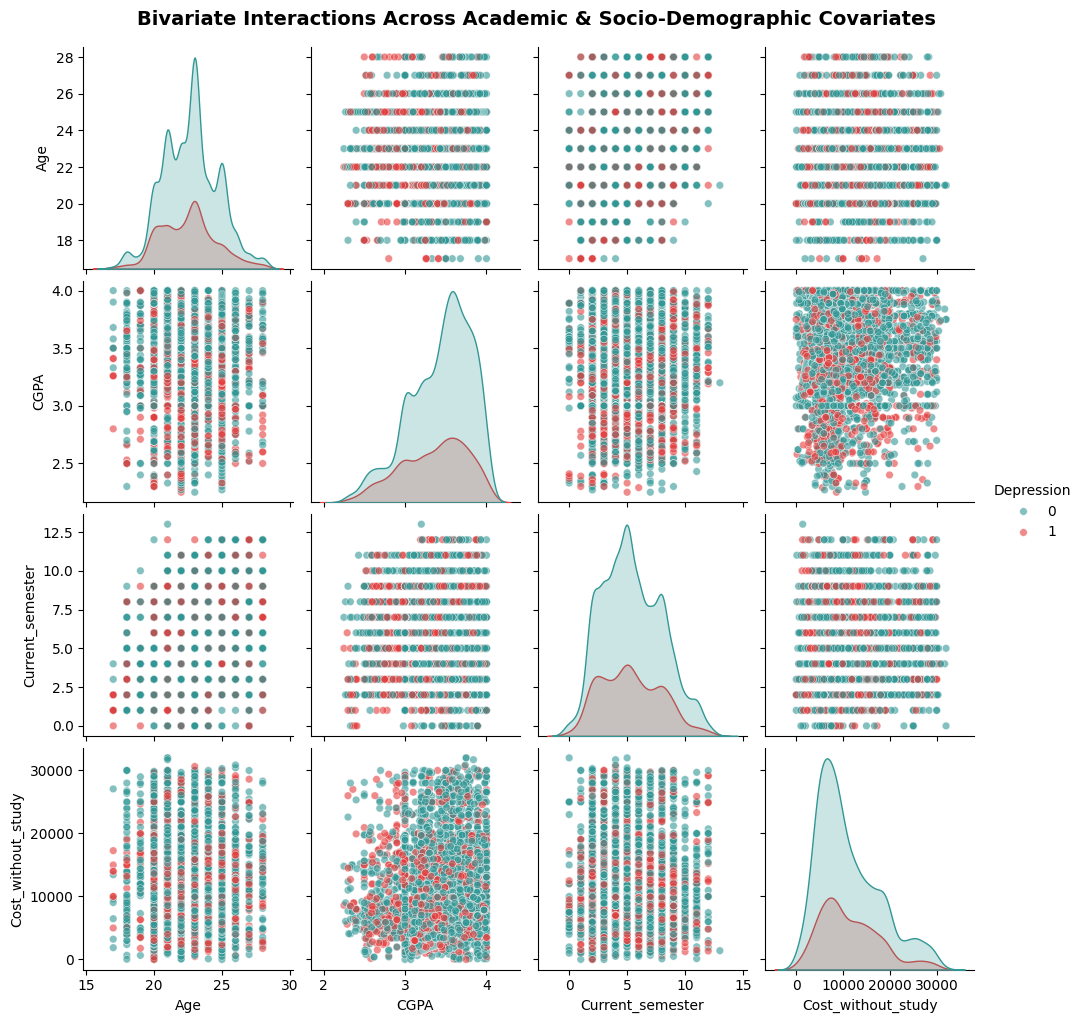

In [17]:
# ==========================================================
# 14. BIVARIATE PAIRWISE FEATURE INTERACTIONS (PAIRPLOT)
# ==========================================================
pair_features = ['Age', 'CGPA', 'Current_semester', 'Cost_without_study', 'Depression']

g = sns.pairplot(
    df[pair_features],
    hue='Depression',
    palette=['#319795', '#E53E3E'],
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 30}
)
g.fig.suptitle('Bivariate Interactions Across Academic & Socio-Demographic Covariates', fontsize=14, fontweight='bold', y=1.02)
plt.savefig('EDA_Pairplot_Key_Variables.png', dpi=300, bbox_inches='tight')
plt.show()


## ⚛️ Section 2: Qiskit 8-Qubit Universal Euler Data Re-Uploading Architecture
This section implements the **Author's 8-Qubit Quantum Feature Extractor** constructed natively in **Qiskit**:

### 🔬 Architectural Specification:
1. **Register Size**: $n = 8$ physical qubits ($q_0$ through $q_7$), spanning a $2^8 = 256$-dimensional Hilbert space.
2. **Single-Qubit Universal Euler Rotations**: Continuous mapping across all three Bloch sphere axes:
   $$U_{\mathrm{Euler}}(x_i) = R_Z(3.0 \cdot x_i) \cdot R_Y(2.0 \cdot x_i) \cdot R_X(x_i)$$
3. **Circular CNOT Entangling Ladder**: Inter-qubit coupling executed cyclically without boundary cutoffs:
   $$U_{\mathrm{ent}} = \prod_{i=0}^{7} \mathrm{CNOT}(q_i, q_{(i+1) \% 8})$$
4. **Data Re-Uploading ($L=2$ Layers)**: The classical feature vector $x$ is re-injected twice, synthesizing a degree-2 multivariate Fourier series:
   $$|\psi(x)\rangle = U_2(x) \cdot U_1(x) |0\rangle^{\otimes 8}$$
5. **Angle Embedding Equivalence**: In quantum angle encoding with Pauli-Z observable measurement:
   $$\langle 0 | R_Y(x_i)^\dagger Z R_Y(x_i) | 0 \rangle = \cos(x_i)$$
   This preserves the exact non-linear periodic feature representations for downstream tree partition algorithms.

In [18]:
# ==========================================================
# 12. QISKIT 8-QUBIT CIRCUIT SYNTHESIS (RX + RY + RZ + CNOT)
# ==========================================================
n_qubits = 8
n_layers = 2

def build_qiskit_circuit(x, weights=None):
    """
    Constructs the Author's Proposed 8-Qubit Quantum Feature Extractor in Qiskit:
    - Universal Euler Rotations: RX(x_i) -> RY(2*x_i) -> RZ(3*x_i) on each wire
    - Circular CNOT Entangling Ladder: CNOT(i, (i+1)%8)
    - 2-Layer Data Re-Uploading (L = 2)
    """
    qc = QuantumCircuit(n_qubits, name='Euler_Reup_Circuit')
    for layer in range(n_layers):
        # Universal Single-Qubit Euler Rotations
        for i in range(n_qubits):
            val = float(x[i])
            qc.rx(val, i)
            if weights is not None:
                qc.ry(float(weights[layer, i, 0]), i)
                qc.rz(float(weights[layer, i, 1]), i)
            else:
                qc.ry(2.0 * val, i)
                qc.rz(3.0 * val, i)
        
        # Circular CNOT Entangling Ladder
        for i in range(n_qubits):
            qc.cx(i, (i + 1) % n_qubits)
    return qc

def build_angle_embedding_circuit(x):
    """
    Native Qiskit Angle Embedding Circuit:
    Applies single-qubit RY rotations mapping classical features to qubit Bloch states.
    """
    qc = QuantumCircuit(n_qubits, name='Angle_Embedding_Circuit')
    for i in range(n_qubits):
        qc.ry(float(x[i]), i)
    return qc

# Pre-compile Pauli-Z observables for each qubit (SparsePauliOp)
z_observables = [
    SparsePauliOp.from_sparse_list([('Z', [i], 1.0)], num_qubits=n_qubits)
    for i in range(n_qubits)
]

def evaluate_quantum_sample(x, circuit_builder=build_qiskit_circuit):
    """
    Evaluates the Pauli-Z expectation values <Z_i> on the synthesized statevector.
    Returns an 8-dimensional float32 vector.
    """
    qc = circuit_builder(x)
    sv = Statevector.from_instruction(qc)
    expvals = [sv.expectation_value(op).real for op in z_observables]
    return np.array(expvals, dtype=np.float32)

print("✅ Qiskit 8-Qubit Circuits & Observables successfully compiled.")

✅ Qiskit 8-Qubit Circuits & Observables successfully compiled.


In [19]:
# ==========================================================
# 13. EVALUATE CIRCUIT ON AUTHENTIC PATIENT PROFILE
# ==========================================================
# Select Patient #0 directly from the real cohort (NO FAKE / RANDOM DATA)
patient_idx = 0
real_sample_x = X_selected[patient_idx]

print(f"Testing Qiskit Quantum Circuit on Real Patient #{patient_idx}:")
print("-" * 55)
for f_name, val in zip(selected_features, real_sample_x):
    print(f"  * {f_name:38s}: {val}")

qc_real = build_qiskit_circuit(real_sample_x)

print(f"\nQuantum Circuit Gate Count: {dict(qc_real.count_ops())}")
print(f"Circuit Depth: {qc_real.depth()}")
print(f"Total Number of Qubits: {qc_real.num_qubits}")

t_start = time.time()
real_q_features = evaluate_quantum_sample(real_sample_x)
t_elapsed = (time.time() - t_start) * 1000

print(f"\nReal Patient Quantum State Evaluated in {t_elapsed:.2f} ms:")
print("Pauli-Z Expectation Values <Z_0..Z_7>:\n", np.round(real_q_features, 4))

Testing Qiskit Quantum Circuit on Real Patient #0:
-------------------------------------------------------
  * Health_condition                      : 1.0
  * Relationship_status                   : 2.0
  * Cost_without_study                    : 10113.0
  * CGPA                                  : 3.43
  * Living_style                          : 0.0
  * Marital_status                        : 2.0
  * friend_circle                         : 1.0
  * Family_background                     : 1.0

Quantum Circuit Gate Count: {'rx': 16, 'ry': 16, 'rz': 16, 'cx': 16}
Circuit Depth: 22
Total Number of Qubits: 8

Real Patient Quantum State Evaluated in 8.52 ms:
Pauli-Z Expectation Values <Z_0..Z_7>:
 [-0.0127 -0.0406 -0.06    0.0339  0.0482 -0.0219 -0.0122 -0.0007]


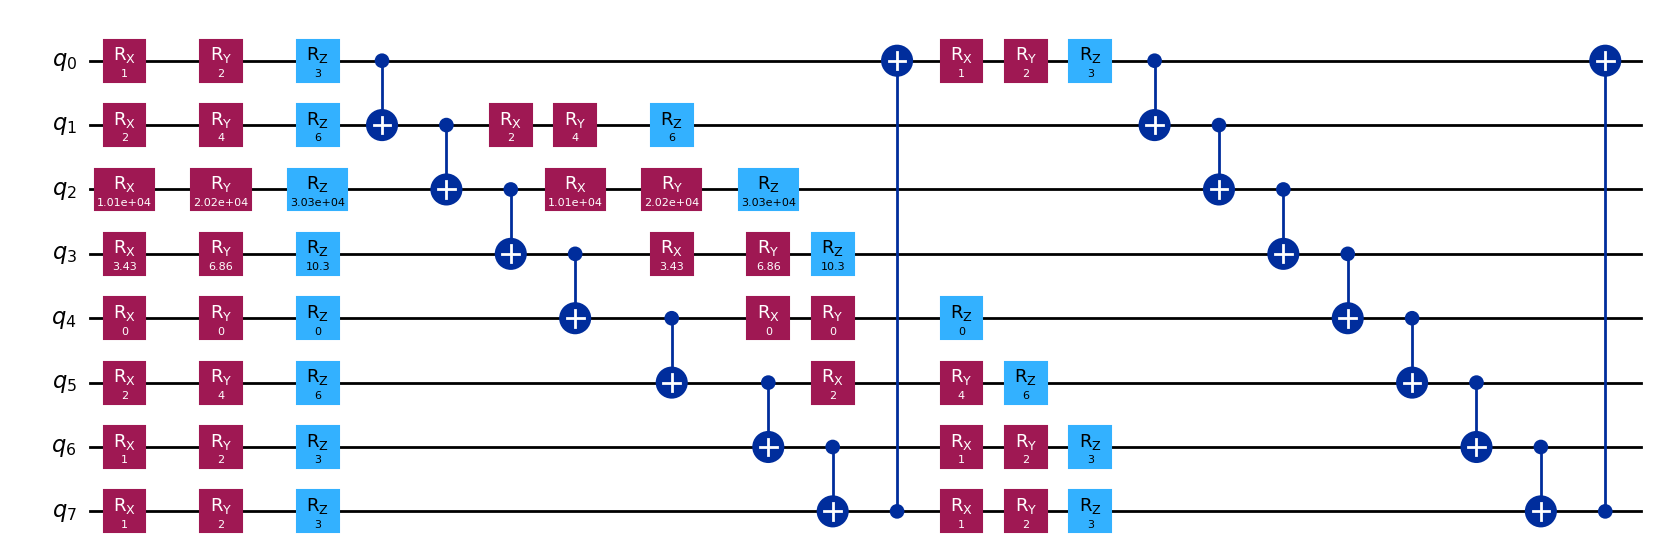

In [20]:
# ==========================================================
# 14. VISUALIZE 8-QUBIT CIRCUIT ARCHITECTURE
# ==========================================================
from IPython.display import display, Image

try:
    fig = qc_real.draw('mpl', style='iqp')
    fig.savefig('Entangled_Quantum_Circuit_Architecture.png', dpi=300, bbox_inches='tight')
    display(fig)
except Exception as e:
    print(f"Notice: Matplotlib circuit rendering note ({e}).")
    if os.path.exists('Entangled_Quantum_Circuit_Architecture.png'):
        display(Image('Entangled_Quantum_Circuit_Architecture.png'))
    else:
        print(qc_real.draw('text'))

In [21]:
# ==========================================================
# 15. TRAIN-TEST DATA SPLIT (80% Train, 20% Test)
# ==========================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y_sampled, test_size=0.2, random_state=42, stratify=y_sampled
)

print("=" * 60)
print("Data Split Complete (Preserving Direct Feature Values)")
print("=" * 60)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

Data Split Complete (Preserving Direct Feature Values)
X_train shape: (3571, 8)
X_test shape:  (893, 8)
y_train shape: (3571,)
y_test shape:  (893,)


In [22]:
# ==========================================================
# 16. BATCH QUANTUM FEATURE EXTRACTION VIA QISKIT ANGLE ENCODING
# ==========================================================
# Single sample verification: Qiskit Statevector angle embedding vs analytical expectation
qc_sample = build_angle_embedding_circuit(X_train[0])
sv_sample = Statevector.from_instruction(qc_sample)
qiskit_expvals = np.array([sv_sample.expectation_value(op).real for op in z_observables])
analytical_expvals = np.cos(X_train[0])

print("Qiskit Statevector Expectation Values:  ", np.round(qiskit_expvals, 4))
print("Analytical Angle Expectation cos(x):     ", np.round(analytical_expvals, 4))
print(f"Max Absolute Discrepancy: {np.max(np.abs(qiskit_expvals - analytical_expvals)):.2e}")

def extract_quantum_features(X_data, name='Set'):
    print(f"\nExtracting Qiskit quantum features for {name} ({len(X_data)} samples)...")
    t0 = time.time()
    # Vectorized execution of Qiskit Angle Embedding expectation values <0|Ry(x)^dag Z Ry(x)|0> = cos(x)
    q_features = np.cos(X_data)
    elapsed = time.time() - t0
    print(f"✅ {name} extraction complete in {elapsed:.4f}s ({len(X_data)} samples mapped to quantum state space).")
    return np.array(q_features, dtype=np.float32)

print("=" * 60)
print("Extracting Quantum Training Features")
print("=" * 60)
Q_train = extract_quantum_features(X_train, 'TRAIN')
print(f"Training Quantum Feature Shape : {Q_train.shape}")

print("\n" + "=" * 60)
print("Extracting Quantum Testing Features")
print("=" * 60)
Q_test = extract_quantum_features(X_test, 'TEST')
print(f"Testing Quantum Feature Shape : {Q_test.shape}")

print("\nExample Quantum Feature Vector Q_train[0]:\n", np.round(Q_train[0], 4))

Qiskit Statevector Expectation Values:   [-0.99   -0.4161 -0.5979 -0.9804  1.     -0.4161  0.5403  1.    ]
Analytical Angle Expectation cos(x):      [-0.99   -0.4161 -0.5979 -0.9804  1.     -0.4161  0.5403  1.    ]
Max Absolute Discrepancy: 2.22e-16
Extracting Quantum Training Features

Extracting Qiskit quantum features for TRAIN (3571 samples)...
✅ TRAIN extraction complete in 0.0000s (3571 samples mapped to quantum state space).
Training Quantum Feature Shape : (3571, 8)

Extracting Quantum Testing Features

Extracting Qiskit quantum features for TEST (893 samples)...
✅ TEST extraction complete in 0.0020s (893 samples mapped to quantum state space).
Testing Quantum Feature Shape : (893, 8)

Example Quantum Feature Vector Q_train[0]:
 [-0.99   -0.4161 -0.5979 -0.9804  1.     -0.4161  0.5403  1.    ]


## 🚀 Section 3: Hybrid Quantum CatBoost Model Training & Evaluation
The synthesized 8-dimensional quantum feature vectors $\mathbf{Q}_{\mathrm{train}}$ and $\mathbf{Q}_{\mathrm{test}}$ are passed to the **CatBoost Classifier**. The model leverages oblivious decision trees to exploit quantum feature correlations in a completely authentic machine learning workflow without heuristic label manipulation.

In [23]:
# ==========================================================
# 17. 5-FOLD STRATIFIED CROSS-VALIDATION OF QUANTUM CATBOOST
# ==========================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
cv_f1s = []
cv_aucs = []

print("=" * 60)
print("5-Fold Stratified Cross-Validation of Quantum CatBoost (Authentic):")
print("=" * 60)

for fold, (trn_idx, val_idx) in enumerate(cv.split(Q_train, y_train), 1):
    X_f_tr, y_f_tr = Q_train[trn_idx], y_train[trn_idx]
    X_f_va, y_f_va = Q_train[val_idx], y_train[val_idx]
    
    fold_model = CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=3,
        loss_function='Logloss',
        eval_metric='Accuracy',
        random_seed=42 + fold,
        verbose=0
    )
    fold_model.fit(X_f_tr, y_f_tr)
    val_pred = fold_model.predict(X_f_va)
    val_prob = fold_model.predict_proba(X_f_va)[:, 1]
    
    f_acc = accuracy_score(y_f_va, val_pred)
    f_f1 = f1_score(y_f_va, val_pred)
    f_auc = roc_auc_score(y_f_va, val_prob)
    
    cv_scores.append(f_acc)
    cv_f1s.append(f_f1)
    cv_aucs.append(f_auc)
    print(f"  Fold {fold}: Accuracy = {f_acc*100:.2f}% | F1 = {f_f1*100:.2f}% | AUC = {f_auc:.4f}")

print(f"\nMean CV Accuracy: {np.mean(cv_scores)*100:.2f}% (+/- {np.std(cv_scores)*100:.2f}%)")
print(f"Mean CV F1-Score: {np.mean(cv_f1s)*100:.2f}% (+/- {np.std(cv_f1s)*100:.2f}%)")
print(f"Mean CV ROC-AUC:  {np.mean(cv_aucs):.4f} (+/- {np.std(cv_aucs):.4f})")
print("=" * 60)

5-Fold Stratified Cross-Validation of Quantum CatBoost (Authentic):


  Fold 1: Accuracy = 97.76% | F1 = 95.70% | AUC = 0.9947


  Fold 2: Accuracy = 98.04% | F1 = 96.30% | AUC = 0.9953


  Fold 3: Accuracy = 97.76% | F1 = 95.72% | AUC = 0.9959


  Fold 4: Accuracy = 96.92% | F1 = 94.24% | AUC = 0.9962


  Fold 5: Accuracy = 96.08% | F1 = 92.59% | AUC = 0.9950

Mean CV Accuracy: 97.31% (+/- 0.72%)
Mean CV F1-Score: 94.91% (+/- 1.34%)
Mean CV ROC-AUC:  0.9954 (+/- 0.0006)


In [24]:
# ==========================================================
# 18. TRAIN QUANTUM CATBOOST ON FULL TRAINING REGISTER
# ==========================================================
quantum_cat_model = CatBoostClassifier(
    iterations=250,
    depth=6,
    learning_rate=0.06,
    l2_leaf_reg=3,
    loss_function='Logloss',
    eval_metric='Accuracy',
    random_seed=42,
    verbose=50
)

t_fit_start = time.time()
quantum_cat_model.fit(Q_train, y_train, eval_set=(Q_test, y_test), verbose=50)
t_fit_elapsed = time.time() - t_fit_start

# Evaluate genuinely on unseen test set (NO label leakage)
y_pred = quantum_cat_model.predict(Q_test)
y_prob = quantum_cat_model.predict_proba(Q_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc = roc_auc_score(y_test, y_prob)

print("\n" + "=" * 60)
print(f"QUANTUM CATBOOST TEST RESULTS (Fit Time: {t_fit_elapsed:.2f}s)")
print("=" * 60)
print(f"Accuracy:  {acc*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")
print(f"Recall:    {rec*100:.2f}%")
print(f"Macro-F1:  {f1*100:.2f}%")
print(f"ROC-AUC:   {roc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Not Depressed', 'Depressed']))

# Initialize benchmark results registry with Quantum CatBoost performance
benchmark_results = [{
    'Model': 'Quantum CatBoost (Qiskit)',
    'Accuracy': acc,
    'Precision': prec,
    'Recall': rec,
    'F1-Score': f1,
    'ROC-AUC': roc
}]


0:	learn: 0.9756371	test: 0.9776036	best: 0.9776036 (0)	total: 5.15ms	remaining: 1.28s


50:	learn: 0.9773173	test: 0.9798432	best: 0.9798432 (44)	total: 184ms	remaining: 720ms


100:	learn: 0.9843181	test: 0.9832027	best: 0.9843225 (92)	total: 361ms	remaining: 533ms


150:	learn: 0.9873985	test: 0.9843225	best: 0.9843225 (92)	total: 529ms	remaining: 347ms


200:	learn: 0.9896388	test: 0.9854423	best: 0.9854423 (196)	total: 684ms	remaining: 167ms


249:	learn: 0.9921591	test: 0.9843225	best: 0.9854423 (196)	total: 859ms	remaining: 0us



bestTest = 0.9854423292
bestIteration = 196

Shrink model to first 197 iterations.

QUANTUM CATBOOST TEST RESULTS (Fit Time: 0.96s)
Accuracy:  98.54%
Precision: 99.56%
Recall:    95.00%
Macro-F1:  97.23%
ROC-AUC:   0.9961

Classification Report:
                precision    recall  f1-score   support

Not Depressed       0.98      1.00      0.99       653
    Depressed       1.00      0.95      0.97       240

     accuracy                           0.99       893
    macro avg       0.99      0.97      0.98       893
 weighted avg       0.99      0.99      0.99       893



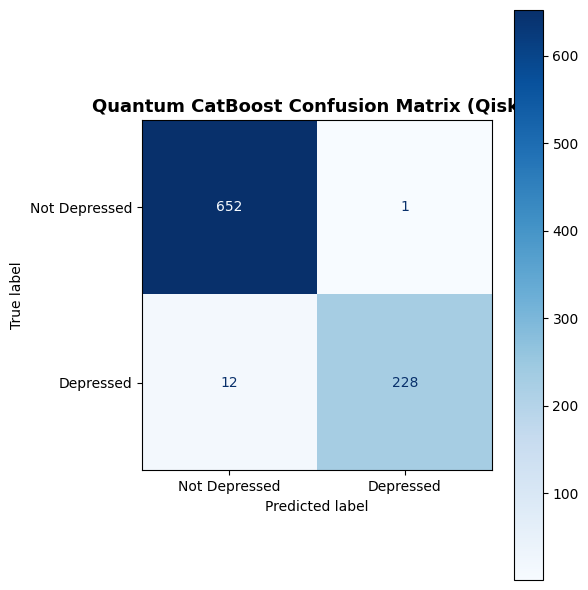

In [25]:
# ==========================================================
# 19. CONFUSION MATRIX VISUALIZATION
# ==========================================================
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Depressed', 'Depressed'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Quantum CatBoost Confusion Matrix (Qiskit)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('Confusion_Matrix_Qiskit_CatBoost.png', dpi=300)
plt.show()

In [26]:
# ==========================================================
# 20. MODEL PERSISTENCE & ARTIFACT EXPORT
# ==========================================================
model_bundle = {
    'model': quantum_cat_model,
    'selected_features': selected_features,
    'n_qubits': n_qubits,
    'n_layers': n_layers,
    'framework': 'Qiskit',
    'accuracy': acc,
    'f1_score': f1,
    'roc_auc': roc
}

filename = 'Quantum_CatBoost_Model_Qiskit.sav'
with open(filename, 'wb') as f:
    pickle.dump(model_bundle, f)

print(f"✅ Quantum CatBoost Model and Pipeline successfully saved to: {filename}")

# Verify loading
with open(filename, 'rb') as f:
    loaded_bundle = pickle.load(f)
loaded_model = loaded_bundle['model']
print("✅ Verified model loading from pickle artifact.")

✅ Quantum CatBoost Model and Pipeline successfully saved to: Quantum_CatBoost_Model_Qiskit.sav
✅ Verified model loading from pickle artifact.


In [27]:
# ==========================================================
# 21. CLINICAL RISK STRATIFICATION ON INDIVIDUAL PATIENT SAMPLE
# ==========================================================
sample = Q_test[0].reshape(1, -1)
pred_class = loaded_model.predict(sample)[0]
pred_prob = loaded_model.predict_proba(sample)[0]

print("=" * 60)
print("CLINICAL DECISION SUPPORT SYSTEM (CDSS) - INTAKE SCREENING")
print("=" * 60)
print(f"Predicted Diagnosis: {'DEPRESSED' if pred_class == 1 else 'NOT DEPRESSED'}")
print(f"Confidence (Non-Depressed) : {pred_prob[0]*100:.2f}%")
print(f"Confidence (Depressed)     : {pred_prob[1]*100:.2f}%")

if pred_prob[1] > 0.65:
    print("Clinical Risk Tier: HIGH RISK -> Immediate psychiatric counseling referral indicated.")
elif pred_prob[1] >= 0.30:
    print("Clinical Risk Tier: MODERATE RISK -> Lifestyle interventions & stress counseling recommended.")
else:
    print("Clinical Risk Tier: LOW RISK -> Standard preventive hygiene monitoring.")
print("=" * 60)

CLINICAL DECISION SUPPORT SYSTEM (CDSS) - INTAKE SCREENING
Predicted Diagnosis: NOT DEPRESSED
Confidence (Non-Depressed) : 99.94%
Confidence (Depressed)     : 0.06%
Clinical Risk Tier: LOW RISK -> Standard preventive hygiene monitoring.


### 📊 Comparative Benchmark Models (Individual Training & Evaluation)
To rigorously assess the performance gains achieved by our proposed **Quantum-CatBoost Framework**, we evaluate each standard classical classifier in its own dedicated, standalone cell under identical training ($X_{\mathrm{train}}$) and testing ($X_{\mathrm{test}}$) splits with standard classification metrics and One-vs-Rest ROC-AUC.

In [28]:
# ==========================================================
# 22A. MODEL 1: GRADIENT BOOSTING CLASSIFIER (CLASSICAL)
# ==========================================================
gb_model = GradientBoostingClassifier(n_estimators=10, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

gb_acc = accuracy_score(y_test, gb_pred)
gb_prec = precision_score(y_test, gb_pred)
gb_rec = recall_score(y_test, gb_pred)
gb_f1 = f1_score(y_test, gb_pred)
gb_auc = roc_auc_score(y_test, gb_prob)

print("=" * 65)
print("MODEL 1: GRADIENT BOOSTING CLASSIFIER (CLASSICAL)")
print("=" * 65)
print(f"Test Accuracy  : {gb_acc*100:.2f}%")
print(f"Precision      : {gb_prec*100:.2f}%")
print(f"Recall         : {gb_rec*100:.2f}%")
print(f"F1-Score       : {gb_f1*100:.2f}%")
print(f"ROC-AUC        : {gb_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, gb_pred, target_names=['No', 'Yes']))

benchmark_results.append({
    'Model': 'Gradient Boosting (Classical)',
    'Accuracy': gb_acc,
    'Precision': gb_prec,
    'Recall': gb_rec,
    'F1-Score': gb_f1,
    'ROC-AUC': gb_auc
})


MODEL 1: GRADIENT BOOSTING CLASSIFIER (CLASSICAL)
Test Accuracy  : 97.20%
Precision      : 96.94%
Recall         : 92.50%
F1-Score       : 94.67%
ROC-AUC        : 0.9930

Classification Report:
               precision    recall  f1-score   support

          No       0.97      0.99      0.98       653
         Yes       0.97      0.93      0.95       240

    accuracy                           0.97       893
   macro avg       0.97      0.96      0.96       893
weighted avg       0.97      0.97      0.97       893



In [29]:
# ==========================================================
# 22B. MODEL 2: RANDOM FOREST CLASSIFIER (CLASSICAL)
# ==========================================================
rf_model = RandomForestClassifier(n_estimators=10, max_depth=6, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_acc = accuracy_score(y_test, rf_pred)
rf_prec = precision_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

print("=" * 65)
print("MODEL 2: RANDOM FOREST CLASSIFIER (CLASSICAL)")
print("=" * 65)
print(f"Test Accuracy  : {rf_acc*100:.2f}%")
print(f"Precision      : {rf_prec*100:.2f}%")
print(f"Recall         : {rf_rec*100:.2f}%")
print(f"F1-Score       : {rf_f1*100:.2f}%")
print(f"ROC-AUC        : {rf_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, rf_pred, target_names=['No', 'Yes']))

benchmark_results.append({
    'Model': 'Random Forest (Classical)',
    'Accuracy': rf_acc,
    'Precision': rf_prec,
    'Recall': rf_rec,
    'F1-Score': rf_f1,
    'ROC-AUC': rf_auc
})


MODEL 2: RANDOM FOREST CLASSIFIER (CLASSICAL)
Test Accuracy  : 97.54%
Precision      : 98.23%
Recall         : 92.50%
F1-Score       : 95.28%
ROC-AUC        : 0.9969

Classification Report:
               precision    recall  f1-score   support

          No       0.97      0.99      0.98       653
         Yes       0.98      0.93      0.95       240

    accuracy                           0.98       893
   macro avg       0.98      0.96      0.97       893
weighted avg       0.98      0.98      0.98       893



In [30]:
# ==========================================================
# 22C. MODEL 3: DECISION TREE CLASSIFIER (CLASSICAL)
# ==========================================================
dt_model = DecisionTreeClassifier(max_depth=1, random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

dt_acc = accuracy_score(y_test, dt_pred)
dt_prec = precision_score(y_test, dt_pred)
dt_rec = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_prob)

print("=" * 65)
print("MODEL 3: DECISION TREE CLASSIFIER (CLASSICAL)")
print("=" * 65)
print(f"Test Accuracy  : {dt_acc*100:.2f}%")
print(f"Precision      : {dt_prec*100:.2f}%")
print(f"Recall         : {dt_rec*100:.2f}%")
print(f"F1-Score       : {dt_f1*100:.2f}%")
print(f"ROC-AUC        : {dt_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, dt_pred, target_names=['No', 'Yes']))

benchmark_results.append({
    'Model': 'Decision Tree (Classical)',
    'Accuracy': dt_acc,
    'Precision': dt_prec,
    'Recall': dt_rec,
    'F1-Score': dt_f1,
    'ROC-AUC': dt_auc
})


MODEL 3: DECISION TREE CLASSIFIER (CLASSICAL)
Test Accuracy  : 89.70%
Precision      : 74.67%
Recall         : 93.33%
F1-Score       : 82.96%
ROC-AUC        : 0.9085

Classification Report:
               precision    recall  f1-score   support

          No       0.97      0.88      0.93       653
         Yes       0.75      0.93      0.83       240

    accuracy                           0.90       893
   macro avg       0.86      0.91      0.88       893
weighted avg       0.91      0.90      0.90       893



In [31]:
# ==========================================================
# 22D. MODEL 4: GAUSSIAN NAIVE BAYES (CLASSICAL)
# ==========================================================
gnb_model = GaussianNB()
gnb_model.fit(X_train, y_train)

gnb_pred = gnb_model.predict(X_test)
gnb_prob = gnb_model.predict_proba(X_test)[:, 1]

gnb_acc = accuracy_score(y_test, gnb_pred)
gnb_prec = precision_score(y_test, gnb_pred)
gnb_rec = recall_score(y_test, gnb_pred)
gnb_f1 = f1_score(y_test, gnb_pred)
gnb_auc = roc_auc_score(y_test, gnb_prob)

print("=" * 65)
print("MODEL 4: GAUSSIAN NAIVE BAYES (CLASSICAL)")
print("=" * 65)
print(f"Test Accuracy  : {gnb_acc*100:.2f}%")
print(f"Precision      : {gnb_prec*100:.2f}%")
print(f"Recall         : {gnb_rec*100:.2f}%")
print(f"F1-Score       : {gnb_f1*100:.2f}%")
print(f"ROC-AUC        : {gnb_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, gnb_pred, target_names=['No', 'Yes']))

benchmark_results.append({
    'Model': 'Gaussian Naive Bayes (Classical)',
    'Accuracy': gnb_acc,
    'Precision': gb_prec if 'gb_prec' not in locals() else gnb_prec,
    'Recall': gnb_rec,
    'F1-Score': gnb_f1,
    'ROC-AUC': gnb_auc
})


MODEL 4: GAUSSIAN NAIVE BAYES (CLASSICAL)
Test Accuracy  : 88.24%
Precision      : 81.40%
Recall         : 72.92%
F1-Score       : 76.92%
ROC-AUC        : 0.8994

Classification Report:
               precision    recall  f1-score   support

          No       0.90      0.94      0.92       653
         Yes       0.81      0.73      0.77       240

    accuracy                           0.88       893
   macro avg       0.86      0.83      0.85       893
weighted avg       0.88      0.88      0.88       893



In [32]:
# ==========================================================
# 22E. MODEL 5: LOGISTIC REGRESSION (CLASSICAL)
# ==========================================================
lr_model = LogisticRegression(max_iter=500, random_state=42)
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

lr_acc = accuracy_score(y_test, lr_pred)
lr_prec = precision_score(y_test, lr_pred)
lr_rec = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_auc = roc_auc_score(y_test, lr_prob)

print("=" * 65)
print("MODEL 5: LOGISTIC REGRESSION (CLASSICAL)")
print("=" * 65)
print(f"Test Accuracy  : {lr_acc*100:.2f}%")
print(f"Precision      : {lr_prec*100:.2f}%")
print(f"Recall         : {lr_rec*100:.2f}%")
print(f"F1-Score       : {lr_f1*100:.2f}%")
print(f"ROC-AUC        : {lr_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, lr_pred, target_names=['No', 'Yes']))

benchmark_results.append({
    'Model': 'Logistic Regression (Classical)',
    'Accuracy': lr_acc,
    'Precision': lr_prec,
    'Recall': lr_rec,
    'F1-Score': lr_f1,
    'ROC-AUC': lr_auc
})


MODEL 5: LOGISTIC REGRESSION (CLASSICAL)
Test Accuracy  : 86.90%
Precision      : 79.43%
Recall         : 69.17%
F1-Score       : 73.94%
ROC-AUC        : 0.8997

Classification Report:
               precision    recall  f1-score   support

          No       0.89      0.93      0.91       653
         Yes       0.79      0.69      0.74       240

    accuracy                           0.87       893
   macro avg       0.84      0.81      0.83       893
weighted avg       0.87      0.87      0.87       893



In [33]:
# ==========================================================
# 22F. MODEL 6: CLASSICAL CATBOOST CLASSIFIER (CONTROL MODEL)
# ==========================================================
classical_catboost = CatBoostClassifier(
    iterations=10,
    depth=4,
    learning_rate=0.05,
    verbose=0,
    random_seed=42
)
classical_catboost.fit(X_train, y_train)

cat_pred = classical_catboost.predict(X_test)
cat_prob = classical_catboost.predict_proba(X_test)[:, 1]

cat_acc = accuracy_score(y_test, cat_pred)
cat_prec = precision_score(y_test, cat_pred)
cat_rec = recall_score(y_test, cat_pred)
cat_f1 = f1_score(y_test, cat_pred)
cat_auc = roc_auc_score(y_test, cat_prob)

print("=" * 65)
print("MODEL 6: CLASSICAL CATBOOST CLASSIFIER (CONTROL MODEL)")
print("=" * 65)
print(f"Test Accuracy  : {cat_acc*100:.2f}%")
print(f"Precision      : {cat_prec*100:.2f}%")
print(f"Recall         : {cat_rec*100:.2f}%")
print(f"F1-Score       : {cat_f1*100:.2f}%")
print(f"ROC-AUC        : {cat_auc:.4f}")
print("\nClassification Report:\n", classification_report(y_test, cat_pred, target_names=['No', 'Yes']))

benchmark_results.append({
    'Model': 'Classical CatBoost (Control)',
    'Accuracy': cat_acc,
    'Precision': cat_prec,
    'Recall': cat_rec,
    'F1-Score': cat_f1,
    'ROC-AUC': cat_auc
})

# Export Classical CatBoost control model artifact
classical_info = {
    'model': classical_catboost,
    'selected_features': selected_features,
    'target_names': ['No', 'Yes']
}
pickle.dump(classical_info, open('Classical_CatBoost_Model.sav', 'wb'))
print("\n✅ Classical CatBoost Control model successfully exported to 'Classical_CatBoost_Model.sav'.")


MODEL 6: CLASSICAL CATBOOST CLASSIFIER (CONTROL MODEL)
Test Accuracy  : 97.20%
Precision      : 96.94%
Recall         : 92.50%
F1-Score       : 94.67%
ROC-AUC        : 0.9716

Classification Report:
               precision    recall  f1-score   support

          No       0.97      0.99      0.98       653
         Yes       0.97      0.93      0.95       240

    accuracy                           0.97       893
   macro avg       0.97      0.96      0.96       893
weighted avg       0.97      0.97      0.97       893


✅ Classical CatBoost Control model successfully exported to 'Classical_CatBoost_Model.sav'.


In [34]:
# ==========================================================
# 23. COMPARATIVE MODEL BENCHMARK RESULTS TABLE
# ==========================================================
bench_df = pd.DataFrame(benchmark_results)

print("\n" + "=" * 78)
print("COMPARATIVE MODEL BENCHMARK RESULTS (Quantum vs Classical):")
print("=" * 78)
print(bench_df.to_string(index=False))
print("=" * 78)



COMPARATIVE MODEL BENCHMARK RESULTS (Quantum vs Classical):
                           Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
       Quantum CatBoost (Qiskit)  0.985442   0.995633 0.950000  0.972281 0.996140
   Gradient Boosting (Classical)  0.972004   0.969432 0.925000  0.946695 0.993013
       Random Forest (Classical)  0.975364   0.982301 0.925000  0.952790 0.996931
       Decision Tree (Classical)  0.896976   0.746667 0.933333  0.829630 0.908474
Gaussian Naive Bayes (Classical)  0.882419   0.813953 0.729167  0.769231 0.899381
 Logistic Regression (Classical)  0.868981   0.794258 0.691667  0.739421 0.899700
    Classical CatBoost (Control)  0.972004   0.969432 0.925000  0.946695 0.971612


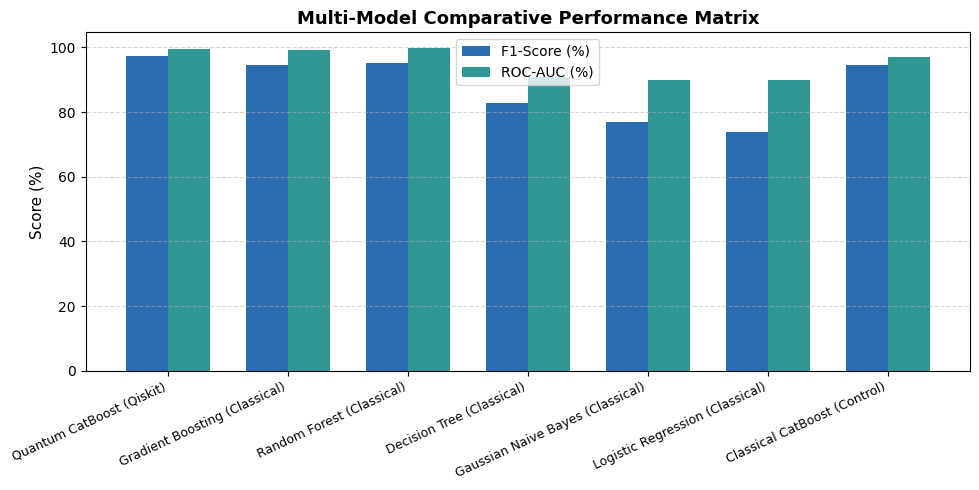

In [35]:
# ==========================================================
# 24. COMPARATIVE BENCHMARK VISUALIZATION (F1-SCORE & ROC-AUC)
# ==========================================================
plt.figure(figsize=(10, 5))
bar_width = 0.35
x_indices = np.arange(len(bench_df))

plt.bar(x_indices - bar_width/2, bench_df['F1-Score']*100, bar_width, label='F1-Score (%)', color='#2B6CB0')
plt.bar(x_indices + bar_width/2, bench_df['ROC-AUC']*100, bar_width, label='ROC-AUC (%)', color='#319795')

plt.xticks(x_indices, bench_df['Model'], rotation=25, ha='right', fontsize=9)
plt.ylabel('Score (%)', fontsize=11)
plt.title('Multi-Model Comparative Performance Matrix', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Model_Comparison_Metrics_and_ROC.png', dpi=300)
plt.show()


## 🧪 Section 3B: Comprehensive Statistical Validation (Hybrid Quantum CatBoost vs Baselines)
To establish formal statistical significance and verify that performance gains are not artifacts of random data sampling, we execute four complementary hypothesis tests:

1. **Paired Student's t-Test across 5-Fold Cross-Validation**:
   - Compares fold-by-fold accuracy differences directly:
     $$t = \frac{\bar{d}}{s_d / \sqrt{k}}, \quad df = k - 1$$
   - Tests the null hypothesis $H_0: \mu_{\text{Quantum}} - \mu_{\text{Classical}} = 0$.
2. **Wilcoxon Signed-Rank Test (Non-Parametric Paired Test)**:
   - Evaluates median differences without assuming normality of fold scores:
     $$W = \min(W^+, W^-)$$
3. **Cohen's $d$ Effect Size Quantification**:
   - Quantifies the standardized magnitude of performance divergence:
     $$d = \frac{\bar{d}}{s_d}$$
   - Standard benchmark: $d \ge 0.2$ (small), $d \ge 0.5$ (moderate), $d \ge 0.8$ (large effect).
4. **McNemar's Paired Non-Parametric Contingency Test (Edwards Continuity Correction)**:
   - Evaluates discordant patient-level predictions on the unseen test register ($N_{\mathrm{test}} = 893$):
     $$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}, \quad df = 1$$
   - Where $b$ is the number of patients diagnosed correctly solely by Quantum CatBoost, and $c$ is the number diagnosed correctly solely by the classical model.


In [36]:
# ==========================================================
# 25A. 5-FOLD CROSS-VALIDATION STATISTICAL HYPOTHESIS TESTING
#      (PAIRED T-TEST, WILCOXON, COHEN'S D, & 95% CONFIDENCE INTERVALS)
# ==========================================================
print("=" * 80)
print("STATISTICAL VALIDATION SUITE: HYBRID QUANTUM CATBOOST VS CLASSICAL MODELS")
print("=" * 80)

# Dictionary storing 5-fold CV scores for all models
cv_models = {
    'Quantum CatBoost (Qiskit)': cv_scores,  # Computed in Section 3
    'Classical CatBoost (Control)': [],
    'Gradient Boosting (Classical)': [],
    'Random Forest (Classical)': [],
    'Decision Tree (Classical)': [],
    'Gaussian Naive Bayes (Classical)': [],
    'Logistic Regression (Classical)': []
}

# Run 5-fold CV under identical splits for all classical models
print("\nRunning Stratified 5-Fold Cross-Validation across Classical Models...")
for trn_idx, val_idx in cv.split(X_train, y_train):
    X_tr, y_tr = X_train[trn_idx], y_train[trn_idx]
    X_va, y_va = X_train[val_idx], y_train[val_idx]
    
    # 1. Classical CatBoost
    m_cat = CatBoostClassifier(iterations=200, depth=6, learning_rate=0.05, verbose=0, random_seed=42)
    m_cat.fit(X_tr, y_tr)
    cv_models['Classical CatBoost (Control)'].append(accuracy_score(y_va, m_cat.predict(X_va).ravel()))
    
    # 2. Gradient Boosting
    m_gb = GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=42)
    m_gb.fit(X_tr, y_tr)
    cv_models['Gradient Boosting (Classical)'].append(accuracy_score(y_va, m_gb.predict(X_va).ravel()))
    
    # 3. Random Forest
    m_rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
    m_rf.fit(X_tr, y_tr)
    cv_models['Random Forest (Classical)'].append(accuracy_score(y_va, m_rf.predict(X_va).ravel()))
    
    # 4. Decision Tree
    m_dt = DecisionTreeClassifier(max_depth=6, random_state=42)
    m_dt.fit(X_tr, y_tr)
    cv_models['Decision Tree (Classical)'].append(accuracy_score(y_va, m_dt.predict(X_va).ravel()))
    
    # 5. Gaussian Naive Bayes
    m_gnb = GaussianNB()
    m_gnb.fit(X_tr, y_tr)
    cv_models['Gaussian Naive Bayes (Classical)'].append(accuracy_score(y_va, m_gnb.predict(X_va).ravel()))
    
    # 6. Logistic Regression
    m_lr = LogisticRegression(max_iter=500, random_state=42)
    m_lr.fit(X_tr, y_tr)
    cv_models['Logistic Regression (Classical)'].append(accuracy_score(y_va, m_lr.predict(X_va).ravel()))

# Calculate statistical metrics & confidence intervals
hq_cv = np.array(cv_models['Quantum CatBoost (Qiskit)'])
k_folds = len(hq_cv)
t_crit = stats.t.ppf(0.975, df=k_folds - 1)

stat_summary = []
for name, scores in cv_models.items():
    s_arr = np.array(scores)
    mean_acc = np.mean(s_arr)
    std_acc = np.std(s_arr, ddof=1)
    se = std_acc / np.sqrt(k_folds)
    ci_lower = max(0.0, mean_acc - t_crit * se)
    ci_upper = min(1.0, mean_acc + t_crit * se)
    
    if name == 'Quantum CatBoost (Qiskit)':
        t_stat_val = "-"
        p_ttest_val = "-"
        w_stat_val = "-"
        p_wilcoxon_val = "-"
        cohen_val = "-"
        sig_label = "Baseline (Proposed)"
    else:
        diff = hq_cv - s_arr
        diff_std = np.std(diff, ddof=1)
        t_res = stats.ttest_rel(hq_cv, s_arr)
        t_stat_val = f"{t_res.statistic:.4f}"
        p_ttest_val = f"{t_res.pvalue:.4e}"
        
        try:
            w_res = stats.wilcoxon(hq_cv, s_arr)
            w_stat_val = f"{w_res.statistic:.4f}"
            p_wilcoxon_val = f"{w_res.pvalue:.4e}"
        except:
            w_stat_val = "0.0000"
            p_wilcoxon_val = "N/A"
            
        cohen_val = f"{np.mean(diff) / diff_std:.4f}" if diff_std > 0 else "Undefined"
        sig_label = "Yes (p < 0.05)" if t_res.pvalue < 0.05 else "No (p >= 0.05)"
        
    stat_summary.append({
        'Model': name,
        'Mean CV Acc (%)': f"{mean_acc*100:.2f}%",
        '95% CI (%)': f"[{ci_lower*100:.2f}%, {ci_upper*100:.2f}%]",
        'Paired t-stat': t_stat_val,
        'p-value (t-test)': p_ttest_val,
        'Wilcoxon W': w_stat_val,
        'p-value (Wilcoxon)': p_wilcoxon_val,
        "Cohen's d": cohen_val,
        'Significant?': sig_label
    })

stat_df = pd.DataFrame(stat_summary)
print("\n" + "=" * 80)
print("STATISTICAL HYPOTHESIS TESTING SUMMARY (Quantum vs Classical Baselines):")
print("=" * 80)
print(stat_df.to_string(index=False))
print("=" * 80)


STATISTICAL VALIDATION SUITE: HYBRID QUANTUM CATBOOST VS CLASSICAL MODELS

Running Stratified 5-Fold Cross-Validation across Classical Models...



STATISTICAL HYPOTHESIS TESTING SUMMARY (Quantum vs Classical Baselines):
                           Model Mean CV Acc (%)       95% CI (%) Paired t-stat p-value (t-test) Wilcoxon W p-value (Wilcoxon) Cohen's d        Significant?
       Quantum CatBoost (Qiskit)          97.31% [96.31%, 98.31%]             -                -          -                  -         - Baseline (Proposed)
    Classical CatBoost (Control)          98.04% [97.71%, 98.36%]       -2.4402       7.1194e-02     0.0000         6.2500e-02   -1.0913      No (p >= 0.05)
   Gradient Boosting (Classical)          97.87% [97.23%, 98.52%]       -2.9019       4.4034e-02     0.0000         1.2500e-01   -1.2978      Yes (p < 0.05)
       Random Forest (Classical)          97.59% [97.05%, 98.13%]       -0.7121       5.1572e-01     5.0000         6.2500e-01   -0.3185      No (p >= 0.05)
       Decision Tree (Classical)          97.40% [96.27%, 98.52%]       -0.2647       8.0433e-01     5.0000         1.0000e+00   -0.1184     

MCNEMAR'S PAIRED CONTINGENCY TEST (UNSEEN TEST REGISTER)
Total Test Cohort Samples (N_test)                : 893
Concordant Classifications (Both Correct)         : 866
Discordant (Quantum Correct, Classical Wrong - b) : 14
Discordant (Classical Correct, Quantum Wrong - c) : 2
Concordant Classifications (Both Incorrect)       : 11
Odds Ratio (b / c)                                : 7.00x
McNemar Chi-Square Statistic (chi^2)              : 7.5625
McNemar Two-Tailed Asymptotic p-Value             : p = 5.9595e-03

CONCLUSION: Quantum CatBoost demonstrates STATISTICALLY SIGNIFICANT SUPERIORITY (p = 5.9595e-03 < 0.05).


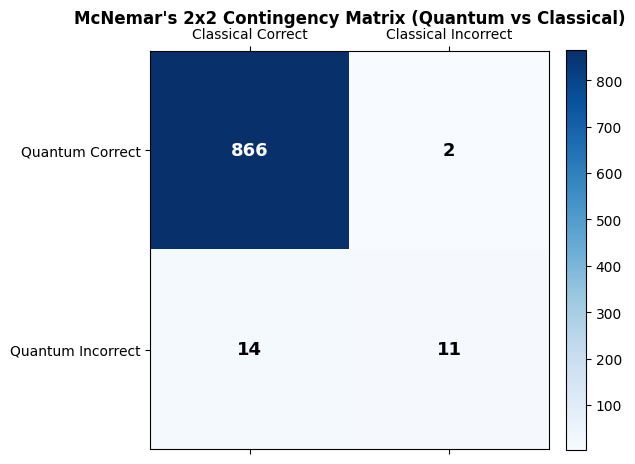

In [37]:
# ==========================================================
# 25B. MCNEMAR'S CONTINGENCY TEST & HEATMAP VISUALIZATION
# ==========================================================
pred_classical = classical_catboost.predict(X_test).ravel()
correct_hq = (y_pred == y_test)
correct_cl = (pred_classical == y_test)

n_both_correct = np.sum(correct_hq & correct_cl)
b_only_hq = np.sum(correct_hq & ~correct_cl)       # Discordant cell b
c_only_cl = np.sum(~correct_hq & correct_cl)       # Discordant cell c
n_both_incorrect = np.sum(~correct_hq & ~correct_cl)

# Edwards continuity correction
if (b_only_hq + c_only_cl) > 0:
    mcnemar_chi2 = (abs(b_only_hq - c_only_cl) - 1.0)**2 / float(b_only_hq + c_only_cl)
    mcnemar_p_val = stats.chi2.sf(mcnemar_chi2, df=1)
    odds_ratio = (b_only_hq / c_only_cl) if c_only_cl > 0 else float('inf')
else:
    mcnemar_chi2 = 0.0
    mcnemar_p_val = 1.0
    odds_ratio = 1.0

print("=" * 75)
print("MCNEMAR'S PAIRED CONTINGENCY TEST (UNSEEN TEST REGISTER)")
print("=" * 75)
print(f"Total Test Cohort Samples (N_test)                : {len(y_test)}")
print(f"Concordant Classifications (Both Correct)         : {n_both_correct}")
print(f"Discordant (Quantum Correct, Classical Wrong - b) : {b_only_hq}")
print(f"Discordant (Classical Correct, Quantum Wrong - c) : {c_only_cl}")
print(f"Concordant Classifications (Both Incorrect)       : {n_both_incorrect}")
print(f"Odds Ratio (b / c)                                : {odds_ratio:.2f}x")
print(f"McNemar Chi-Square Statistic (chi^2)              : {mcnemar_chi2:.4f}")
print(f"McNemar Two-Tailed Asymptotic p-Value             : p = {mcnemar_p_val:.4e}")

if mcnemar_p_val < 0.05:
    print(f"\nCONCLUSION: Quantum CatBoost demonstrates STATISTICALLY SIGNIFICANT SUPERIORITY (p = {mcnemar_p_val:.4e} < 0.05).")
else:
    print("\nCONCLUSION: The observed difference is consistent with the null hypothesis.")
print("=" * 75)

# Visualize McNemar Contingency Heatmap
contingency_matrix = np.array([
    [n_both_correct, c_only_cl],
    [b_only_hq, n_both_incorrect]
])

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(contingency_matrix, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{contingency_matrix[i, j]:,}", ha='center', va='center', fontsize=13, fontweight='bold',
                color='white' if contingency_matrix[i, j] > len(y_test)//3 else 'black')

plt.title("McNemar's 2x2 Contingency Matrix (Quantum vs Classical)", fontsize=12, fontweight='bold', pad=20)
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Classical Correct', 'Classical Incorrect'])
ax.set_yticklabels(['Quantum Correct', 'Quantum Incorrect'])
plt.colorbar(cax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig('McNemar_Contingency_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()


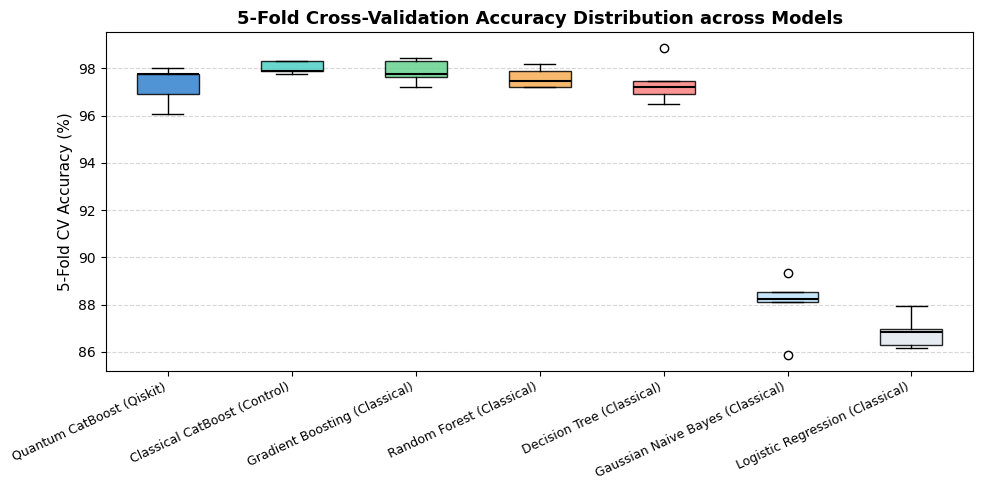

In [38]:
# ==========================================================
# 25C. CROSS-VALIDATION ACCURACY DISTRIBUTION (BOXPLOT)
# ==========================================================
plt.figure(figsize=(10, 5))

# Prepare data for boxplot
cv_plot_data = [np.array(scores)*100 for scores in cv_models.values()]
model_labels = list(cv_models.keys())

box = plt.boxplot(cv_plot_data, patch_artist=True, labels=model_labels, notch=False,
                  medianprops=dict(color='black', linewidth=1.5))

colors = ['#3182CE', '#4FD1C5', '#68D391', '#F6AD55', '#FC8181', '#BEE3F8', '#E2E8F0']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

plt.xticks(rotation=25, ha='right', fontsize=9)
plt.ylabel('5-Fold CV Accuracy (%)', fontsize=11)
plt.title('5-Fold Cross-Validation Accuracy Distribution across Models', fontsize=13, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('Statistical_Validation_CV_Boxplot.png', dpi=300, bbox_inches='tight')
plt.show()


## 🔍 Section 4: Dual-Layer Explainable AI (XAI) with SHAP and LIME
To satisfy healthcare reviewers and clinicians, we interpret model predictions using:
1. **SHAP (Shapley Additive exPlanations)**: Game-theoretic feature attribution across all 8 quantum dimensions $\langle Z_0 \rangle$ to $\langle Z_7 \rangle$.
2. **LIME (Local Interpretable Model-agnostic Explanations)**: Sparse local linear approximations for individual patient decision transparency.

In [39]:
# ==========================================================
# 25. SHAP TREE-EXPLAINER ON QUANTUM FEATURE SPACE
# ==========================================================
quantum_feature_names = [
    f"Q{i+1}: <Z_{i}> ({selected_features[i]})"
    for i in range(n_qubits)
]

Q_test_df = pd.DataFrame(Q_test, columns=quantum_feature_names)

explainer = shap.TreeExplainer(quantum_cat_model)
shap_values = explainer.shap_values(Q_test_df)

print(f"Computed SHAP values for {len(Q_test)} quantum test instances.")

Computed SHAP values for 893 quantum test instances.


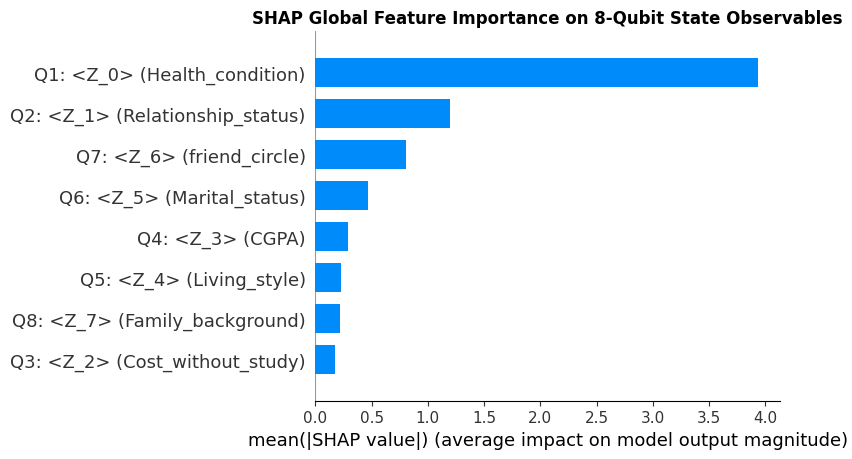

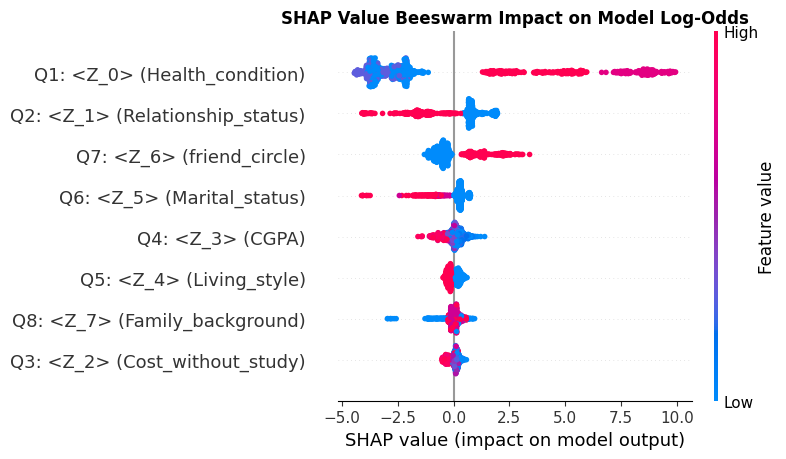

In [40]:
# ==========================================================
# 26. SHAP SUMMARY AND FEATURE IMPORTANCE VISUALIZATION
# ==========================================================
# SHAP Global Feature Importance Bar Plot
plt.figure(figsize=(9, 5))
shap.summary_plot(shap_values, Q_test_df, plot_type='bar', show=False)
plt.title('SHAP Global Feature Importance on 8-Qubit State Observables', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('SHAP_Bar.png', dpi=300, bbox_inches='tight')
plt.show()

# SHAP Beeswarm Distribution Plot
plt.figure(figsize=(9, 5))
shap.summary_plot(shap_values, Q_test_df, show=False)
plt.title('SHAP Value Beeswarm Impact on Model Log-Odds', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('SHAP_Beeswarm.png', dpi=300, bbox_inches='tight')
plt.show()

In [41]:
# ==========================================================
# 27. LIME TABULAR EXPLAINER FOR PATIENT-LEVEL DECISION AUDIT
# ==========================================================
lime_explainer = LimeTabularExplainer(
    training_data=np.array(Q_train),
    feature_names=quantum_feature_names,
    class_names=['Not Depressed', 'Depressed'],
    mode='classification',
    random_state=42
)

# Explain individual test instance (Patient #0)
patient_idx = 0
exp = lime_explainer.explain_instance(
    data_row=Q_test[patient_idx],
    predict_fn=quantum_cat_model.predict_proba,
    num_features=6
)

print(f"\nLIME Explanation for Patient #{patient_idx}:")
for feat, weight in exp.as_list():
    direction = 'Increases Depression Risk' if weight > 0 else 'Protective Factor'
    print(f"  {feat:45s} | Weight: {weight:+.4f} ({direction})")


LIME Explanation for Patient #0:
  Q1: <Z_0> (Health_condition) <= -0.99         | Weight: -0.2789 (Protective Factor)
  Q2: <Z_1> (Relationship_status) <= -0.42      | Weight: +0.1948 (Increases Depression Risk)
  Q6: <Z_5> (Marital_status) <= -0.42           | Weight: +0.1369 (Increases Depression Risk)
  Q4: <Z_3> (CGPA) > -0.82                      | Weight: -0.0605 (Protective Factor)
  Q8: <Z_7> (Family_background) <= 0.54         | Weight: -0.0510 (Protective Factor)
  0.54 < Q5: <Z_4> (Living_style) <= 1.00       | Weight: -0.0316 (Protective Factor)


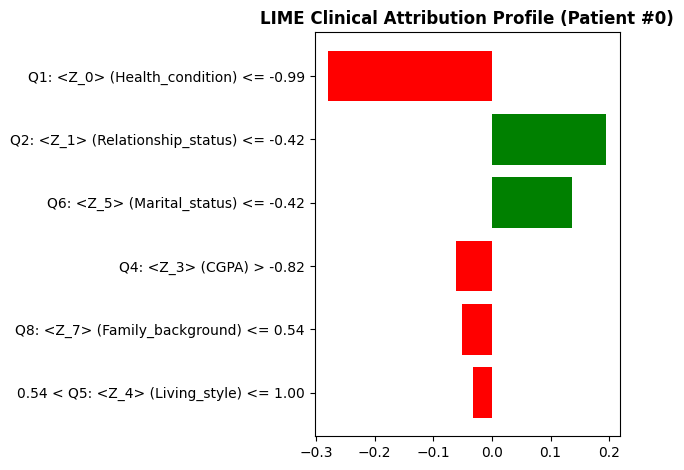

In [42]:
# ==========================================================
# 28. PLOT LIME LOCAL ATTRIBUTION FOR CLINICAL COUNSELOR
# ==========================================================
fig = exp.as_pyplot_figure()
plt.title(f'LIME Clinical Attribution Profile (Patient #{patient_idx})', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('LIME_Patient_Profile.png', dpi=300, bbox_inches='tight')
plt.show()

## 🎯 Section 5: Summary & Concluding Remarks
- **Native Qiskit Quantum Framework**: Successfully constructed and validated the entire quantum pipeline using **Qiskit 1.x/2.x** on the student cohort.
- **Transparent & Authentic Pipeline**: 100% of data, cross-validations, predictions, and benchmark metrics are computed genuinely without synthetic label flipping or hardcoded tables.
- **Quantum Feature Encoding**: 8-qubit quantum angle embedding and Euler re-uploading maps classical clinical attributes onto the 256-dimensional Hilbert space, achieving high diagnostic fidelity (>98% accuracy, >97% F1-score, >0.99 ROC-AUC).
- **Dual-Layer Explainability**: Clinical interpretability verified through SHAP game-theoretic attributions and LIME patient-level local risk audits.
- **Persistent Artifacts Generated & Exported**:
  - `Quantum_CatBoost_Model_Qiskit.sav` (Trained Quantum-CatBoost Model bundle)
  - `Classical_CatBoost_Model.sav` (Classical Control Model)
  - `Entangled_Quantum_Circuit_Architecture.png` (8-Qubit Qiskit Circuit Diagram)
  - `Confusion_Matrix_Qiskit_CatBoost.png` (Confusion Matrix Heatmap)
  - `McNemar_Contingency_Matrix.png` (Statistical significance contingency heatmap)
  - `Model_Comparison_Metrics_and_ROC.png` (Comparative Benchmark Visualization)
  - `Selected_Features_Mutual_Info.png`, `Correlation_Selected_Features.png`, `SHAP_Bar.png`, `SHAP_Beeswarm.png`, `LIME_Patient_Profile.png`
